![title](images/LSSoQS_banner.png)

## Quantum Error Correction - Take Home Project

For the take home project you will get to build you very own quantum error correction decoder. The decoder we will be building in this project is a Belief Propagation decoder (BP). The BP decoder works by iteratively sending messages between data and measurement qubits in a way that allows them to decide on where the physical errors in the circuit is located and thus whether a logical error have occurred.

## Notebook overview

1) Extracting mapping from errors to detection events from a stim circuit

2) Explanation of how the BP decoder works

3) A simple working but inefficient implementation of the BP decoder

4) **The assignment:**

    - You will rewrite the code to create a high performance version of the BP decoder

    - Make a speed comparizon against the inefficient version and show that your version gives the same results, but faster.

    - You will benchmark it against the MWPM (PyMatching) decoder used in the exercises

---

We start by importing a series of python libaries that we will be needing throughout this notebook

In [1]:
import stim
# beliefmatching already have a fully working version of the BP decoder combined with PyMatching,
# we will however make our own and only use one of the libaries functions to convert the error model to the check matrices
# which are needed for the BP decoder. We could make those ourselves as well, but that would be a bit more work and not the main focus of this module.
from beliefmatching import detector_error_model_to_check_matrices
from pymatching import Matching as MWPM
import numpy as np
import matplotlib.pyplot as plt
import helper_functions # Will make our life a bit easier
from time import perf_counter_ns # For accurate timing of the decoding time

## 1. Extracting mapping from errors to detection events from a stim circuit

We start by creating a distance-5 repetition code circuit. You can change it if you want, however, all the settings are tuned for this one so some things could end up taking significantly longer (rquiring higher sample count or compute) so it is recommended that you first go through the nodebook with this QEC code and then afterward if you want you can change it.

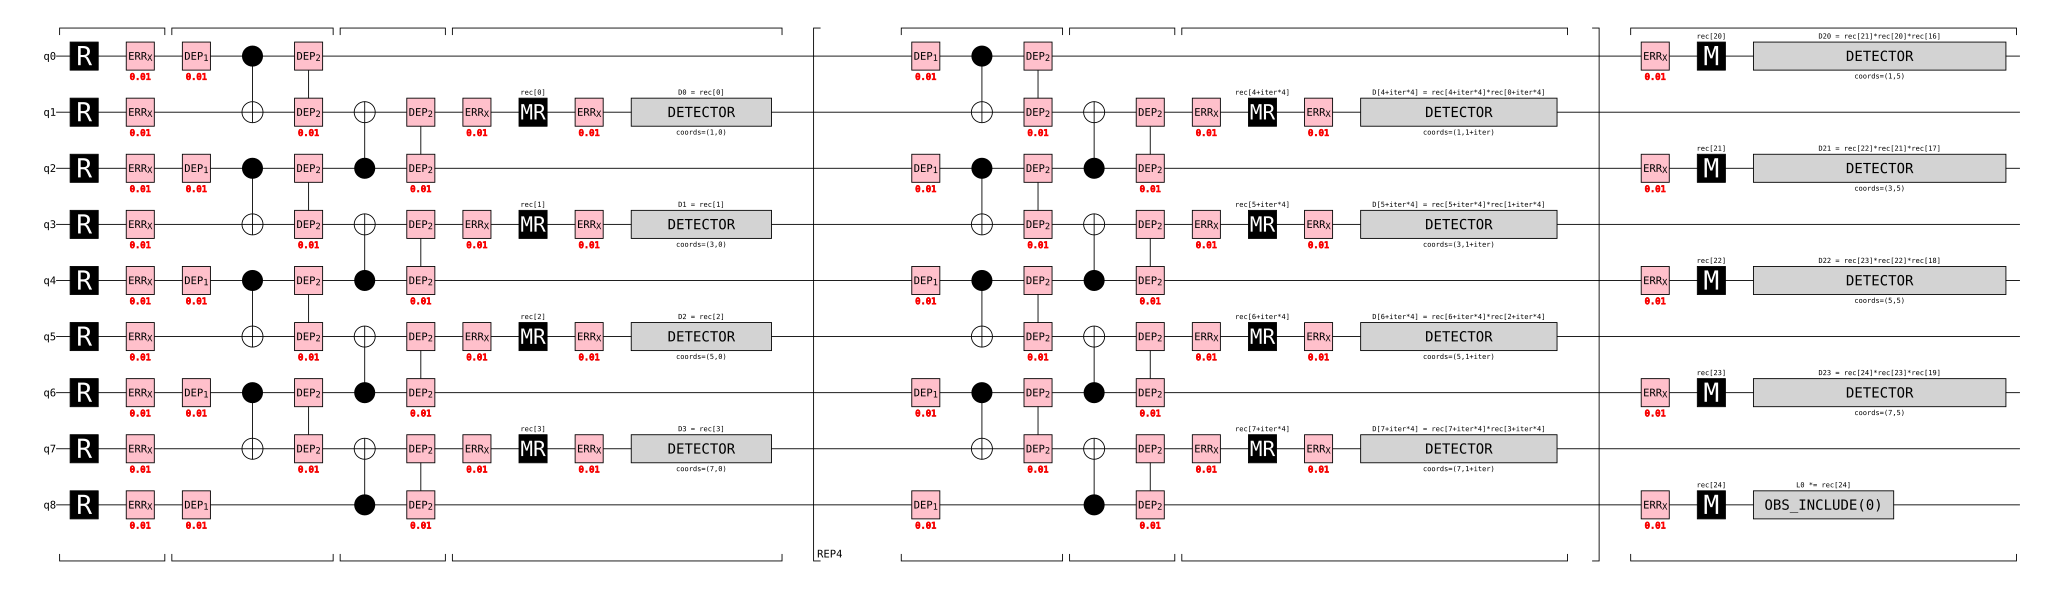

In [2]:
qec_circ = stim.Circuit.generated(
    "repetition_code:memory",
    distance=5,
    rounds=5,
    before_round_data_depolarization=0.01, # With probability p, place a random Pauli error on a given data qubit before each round
    after_clifford_depolarization=0.01, # With probability p, apply a random Pauli error after each gate on the qubits used by that gate (excluding resets and measurements)
    after_reset_flip_probability=0.01, # With probability p, flip the state of the qubit (apply X if the qubit was reset into the Z-basis and Z if it was reset into the X-basis)
    before_measure_flip_probability=0.01 # With probability p, flip the result of a qubit measurement
)
qec_circ.diagram("timeline-svg", rows=None)

Now we will use the `detector_error_model_to_check_matrices` function imported from the `beliefmatching` library to get a check matrix which maps errors to detectors along with varius other usefull information

In [3]:
# Use stim to create a detector error model from the circuit
dem = qec_circ.detector_error_model(decompose_errors=True)
# then use the detector_error_model_to_check_matrices to convert the detector error model in matrices
dem_matrix = detector_error_model_to_check_matrices(dem)

# The check_matrix maps error locations to the detectors
check_matrix = dem_matrix.check_matrix.toarray()
print("Check matrix shape:", check_matrix.shape)

# The observable matrix maps error locations to the logical observable
observable = dem_matrix.observables_matrix.toarray()
print("Observable matrix shape:", observable.shape)

# The priors are the probabilities of an error occurring at each location
priors = dem_matrix.priors
print("Priors shape:", priors.shape)

Check matrix shape: (24, 65)
Observable matrix shape: (1, 65)
Priors shape: (65,)


Let's take a closor look at each of these and look at what information they contain. The following cell will print their information out in a nice readable way. You are of course also welcome to just print them a matrices if you prefere that.

In [4]:
print(f"{'Priors':^{priors.shape[0]*2-1}s}")
hm = int((priors*200).max()/2+1)
for h in range(hm, 0, -1):
    print(' '.join(" " if x <= 2*h-2 else ("▄" if x <= 2*h-1 else "█") for x in np.round(priors*200)))
print(f"{'Check matrix':^{check_matrix.shape[1]*2-1}s}")
for rows in check_matrix:
    print(' '.join('1' if x == 1 else '_' for x in rows))
print(f"{'Observable matrix':^{observable.shape[1]*2-1}s}")
for rows in observable:
    print(' '.join('1' if x == 1 else '_' for x in rows))

                                                             Priors                                                              
    ▄     ▄     ▄   ▄       ▄   ▄   ▄ ▄             ▄   ▄   ▄ ▄             ▄   ▄   ▄ ▄             ▄   ▄   ▄ ▄                  
█ █ █   █ █   █ █   █ █     █   █   █ █             █   █   █ █             █   █   █ █             █   █   █ █         ▄ ▄ ▄ ▄ ▄
█ █ █ ▄ █ █ ▄ █ █ ▄ █ █ █ █ █ █ █ █ █ █ █ ▄ ▄ ▄ █ █ █ █ █ █ █ █ █ ▄ ▄ ▄ █ █ █ █ █ █ █ █ █ ▄ ▄ ▄ █ █ █ █ █ █ █ █ █ ▄ ▄ ▄ █ █ █ █ █
                                                          Check matrix                                                           
1 1 1 1 _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _
_ 1 _ _ 1 1 1 _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _
_ _ _ _ 1 _ _ 1 1 1 _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ _ 

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #7e57c2; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🧠 How to read</h4>

Each column in the print output above represents a location an error could happen at - note that in this case errors are a binary thing and we do not have to worry about the difference between bit-flip and phase-flip errors.

The probability that an error happen at a given point is represented by the hight of the bars (Each full bar-element represents $1\%$). These probabilities are calculated based on the probabilities entered then creating the circuit.

The `Check matrix` gives us a mapping from error locations over to detection events. A given set of errors can be represented with a binary vector (where 1 indicates an error and 0 indicates no error). This error vector can then be acted upon by the check matrix modulo 2 to get a new binary vector representing which detectors would detect those errors. As an example if we have an error at the second location (second column) the first two detectors will fire.

The `Observable matrix` works in the same way as the `Check matrix` except that it tells us if an error affects our logical information. In this case the `Observable matrix` is more like a vector since our code only contains one logical qubit.

</div>


## 2. Explaination of how the BP decoder works

We have two types of nodes that exchange messages (a single float / number). They are:

- **Variable nodes ($v$):** These represent the error locations that we looked at in the above cell (the columns).

- **Check nodes ($c$):** These represents the detectors in our QEC code (the rows in the `Check matrix`).

Note that the nodes themselves do not have any intrinsic values, instead they process incomming messages based on the prior error model and the measured syndrome. We will represent the set of **Variable nodes** $v$ connected to **Check node** $c$ by the set $N(c)$ and the set of **Check nodes** $c$ connected to **Variable node** $v$ by the set $N(v)$.

### The algorithm:

1) Each **Variable node** sends a message 

    \begin{equation}
        m_{v\rightarrow c} = L_0 + \sum_{c'\in N(v) \backslash c} m_{c'\rightarrow v} \qquad L_0 = \log\left(\frac{1-p}{p}\right)
    \end{equation}

    to its connected **Check nodes** with $p$ representing our prior belief that an error will happen at that location. Note that initially all $m_{c'\rightarrow v} = 0$ since no messages have been sent from the **Check nodes** $c$. Also note that for future iterations, the message from node $c$ is not included in the sum for the message back to node $c$ indicated by $c'\in N(v) \backslash c$.

    <details style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #e1f71fff; padding: 12px; border-radius: 6px; margin: 10px 0;">
    <summary><strong>🗒️ Intuition</strong></summary>

    The value of the message $m_{v\rightarrow c}$ sent from the **Variable node** to the **Check node** can be interpreted as how much the **Variable node** beliefs that it has an error.

    - $m_{v\rightarrow c} \ll 0$ This tells the **Check node** that the **Variable node** is very confident that it has an error.

    - $m_{v\rightarrow c} \approx 0$ This tells the **Check node** that the **Variable node** is unsure if it has an error or not.

    - $m_{v\rightarrow c} \gg 0$ This tells the **Check node** that the **Variable node** is very confident that it has no error.

    The $m_{v\rightarrow c}$ message is a combination of the **Variable node's** prior belief $L_0$ and the incomming messages from the connected **Check nodes** which each want to push the **Variable node** in some direction.

    **NOTE:** that we do not include the incomming message from the **Check node** that we are sending to - this is so we avoid a self-amplifying feedback-loop. We can however still get feed-back loops by going through multiple **Variable-** and **Check nodes** which can lead the decoder to not converge to a valid solution. BP is only garanteed to work on a tree-like graph with no loops, the tanner graphs we are working on does however often contain loops meaning BP does not alway give valid solutions (more about that further down)

    </details>

2) Upon recieving the messages from the **Variable nodes**, each **Check node** responds back with the message 

    \begin{equation}
        m_{c\rightarrow v} = (-1)^{s_c} 2 \,\text{arctanh}\left(\prod_{v'\in N(c) \backslash v} \tanh\left(\frac{m_{v'\rightarrow c}}{2}\right)\right)
    \end{equation}

    with $s_c$ the detection result (the syndrome) at **Check node** $c$. Again note that the product $\Pi_{v'\in N(c) \backslash v}$ is over all the messages send to the **Check node** $c$ except the message from the **Variable node** $v$ it is sending a message back to.

    <details style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #e1f71fff; padding: 12px; border-radius: 6px; margin: 10px 0;">
    <summary><strong>🗒️ Intuition</strong></summary>

    The value of the message $m_{c\rightarrow v}$ sent from the **Check node** to the **Variable node** can be interpreted as how much the **Check node** wants to nudge the belief of the **Variable node** in either the direction of having an error or not having an error by sending a positive or negative value respectively.

    Remember that the **Check node** represents a detector in our circuit. If the detector fired $s_c = 1$, the **Check node** wants an odd number of the connected **Variable nodes** to indicate an error. If the detector on the other hand did not fire $s_c = 0$, the **Check node** will want an even number (including zero) of the **Variable nodes** to indicate an error.

    This is achieved by applying a soft XOR (visualized in the plot below for two inputs and implemented with $2 \,\text{arctanh}\left(\prod_{v'\in N(c) \backslash v} \tanh\left(\frac{m_{v'\rightarrow c}}{2}\right)\right)$) to the incomming messages from the **Variable nodes** except the one we are sending to. Here is how the soft XOR works.

    - If an even number of the **Variable nodes** indicate an error ($m_{v'\rightarrow c} \ll 0$) and the rest indicate no error ($m_{v'\rightarrow c} \gg 0$) the soft XOR will have a positive value.

    - If an odd number of the **Variable nodes** indicate an error ($m_{v'\rightarrow c} \ll 0$) and the rest indicate no error ($m_{v'\rightarrow c} \gg 0$) the soft XOR will have a negative value.

    - If just one of the **Variable nodes** indicate its unsure ($m_{v'\rightarrow c} \approx 0$) the soft XOR will take a value of $\approx 0$.

    <img src="images/soft_xor.png" style="height: 500px; margin-right: 1em;">

    In the case of no detection $s_c = 0$ we want the **Variable node** we are sending to to not indicate an error if an even number of the other **Variable nodes** indicate an error, if an odd number of the other **Variable nodes** indicate an error we want the **Variable node** we are sending to to indicate an error so we get an even number of errors, satisfying the check node. In this case we can just send the value of the soft XOR to get this result.

    In the other case we want the exact opposite so the want to send $-1 \times$ soft XOR instead. This is achieved with multiplying the soft XOR result by $(-1)^{s_c}$.

    </details>

3) Step 1 and 2 are repeated until the messages either approximately converge at which point future iteration will not change anything or until some iteration limit is reached (usually 20 iterations are enough to converge).

4) Finally after all the iterations have been completed we will calculate the final belief that an error occurred at each location as: 

    \begin{equation}
        L = L_0 + \sum_{c'\in N(v)} m_{c'\rightarrow v}
    \end{equation}

    with $L$ the log-likelihood ratio that we have an error, which can be converted to a probability with $$p_{err} = \frac{1}{1 + \exp(L)}$$A hard decision can then be made by saying an error occurred at the given locations if $p_{err} > 50\%$ or equivalently $L < 0$. 

It is important to note that the final hard decision obtained from the BP beliefs is not guaranteed to satisfy all parity checks so it is always important to check that the decoding is valid. This can be done by computing the syndrome that would be produced if the predicted errors occurred (Multiplying the hard decision with the check matrix should give the measured syndrome). If that syndrome does not match the measured syndrome when we need to fall back to another decoder like the MWPM (PyMatching) decoder that you have been using in the exercises.

### The fallback:

While it may in some cases be required to fall back to another decoder, that does not mean that the results produced by the BP decoder is useless, we can still use them as valuable soft information for other decoders like the MWPM (PyMatching) decoder. In the case of the MWPM decoder, one of the inputs are edge weights which represents the log-likelihood of an error at a given error location, here instead of using the `priors` to calculate them we can instead use the error likelihoods $p_{err}$ produced by our BP decoder. 

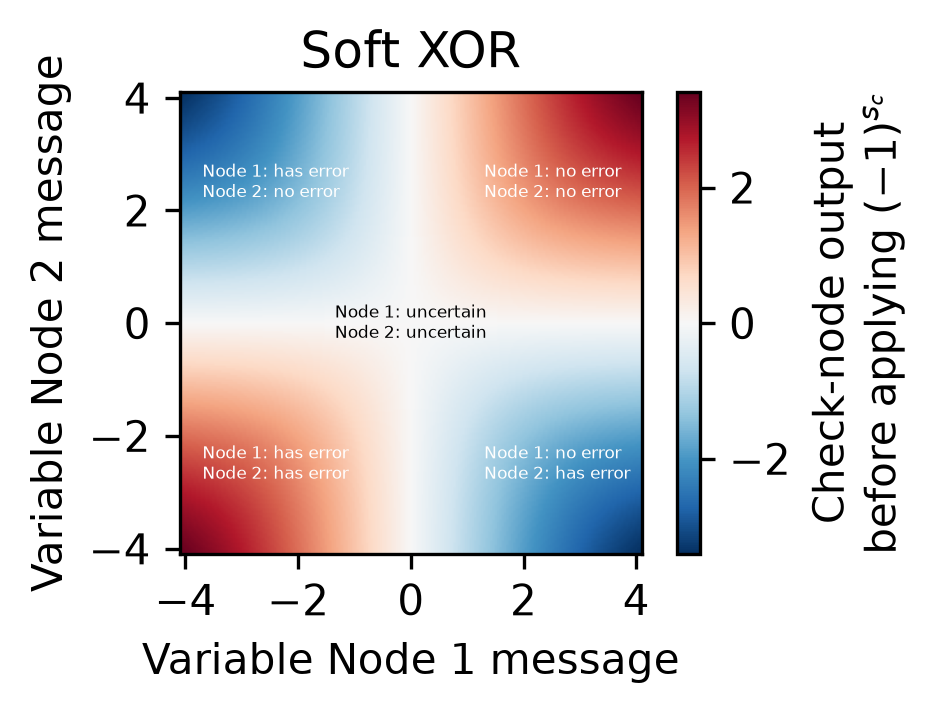

In [5]:
m1 = np.linspace(-4.1, 4.1, 201)
m2 = np.linspace(-4.1, 4.1, 201)
incomming_1, incomming_2 = np.meshgrid(m1, m2)
outgoing_3 = 2*np.arctanh(np.tanh(incomming_1/2) * np.tanh(incomming_2/2))

plt.figure(figsize=(3, 2), dpi=300)
plt.imshow(outgoing_3, cmap='RdBu_r', extent=(-4.1, 4.1, -4.1, 4.1), vmin=-np.abs(outgoing_3).max(), vmax=np.abs(outgoing_3).max(), origin='lower')
plt.colorbar(label='Check-node output\nbefore applying $(-1)^{s_c}$')
plt.title('Soft XOR')
plt.xlabel('Variable Node 1 message')
plt.ylabel('Variable Node 2 message')
plt.xticks([-4, -2, 0, 2, 4])
plt.yticks([-4, -2, 0, 2, 4])
plt.text(2.5-1.2, 2.5, 'Node 1: no error\nNode 2: no error', color='white', fontsize=4, ha='left', va='center')
plt.text(2.5-1.2, -2.5, 'Node 1: no error\nNode 2: has error', color='white', fontsize=4, ha='left', va='center')
plt.text(-2.5-1.2, 2.5, 'Node 1: has error\nNode 2: no error', color='white', fontsize=4, ha='left', va='center')
plt.text(-2.5-1.2, -2.5, 'Node 1: has error\nNode 2: has error', color='white', fontsize=4, ha='left', va='center')
plt.text(0, 0, 'Node 1: uncertain\nNode 2: uncertain', color='black', fontsize=4, ha='center', va='center')
plt.savefig('images/soft_xor.png', bbox_inches='tight', dpi=300)
plt.show()

## 3. A simple working but inefficient implementation of the BP decoder

The `BaseBP` is a fully working version of the Belief Propagation (BP) decoder described above. It is however done using for loops and if statements making it very slow. Your task is to implement a faster version of it using numpy (or jax.numpy for even better performance) and get rid of the for loops. You should use the `BaseBP` to verify that your decoder gives the same results (at least approximately). You should also use it as a reference point to determine how much faster the numpy or jax.numpy version is.

In [6]:
class BaseBP:
    def __init__(self, stim_circuit: stim.Circuit, max_iterations: int = 20):
        """
        A fully working implementation of belief propagation decoding for quantum error correction. 

        The decoder makes use of explicit for loops and if statements to update the messages, 
        which is not optimal for speed but makes it easier to read the code and understand the algorithm. 
        
        The decoder can be used as a baseline to compare against more optimized implementations, 
        such as the NumpyBPDecoder (and possibly the JaxBPDecoder) class that you will implement.
        """
        dem = stim_circuit.detector_error_model(decompose_errors=True)
        self.dem_matrix = detector_error_model_to_check_matrices(dem)
        
        self.check_matrix = self.dem_matrix.check_matrix.toarray()
        self.observable_matrix = self.dem_matrix.observables_matrix.toarray()
        self.error_priors = self.dem_matrix.priors

        self.intrinsic_belief = np.log((1-self.error_priors) / self.error_priors)
        self.max_iterations = max_iterations
        
    # Send messages from variable nodes to check nodes
    def message_from_v_to_c(self, msg_in: np.ndarray) -> np.ndarray:
        msg_out = np.zeros_like(msg_in)
        # Loop over all edges in the Tanner graph and update the messages based on the incoming messages and the intrinsic belief for each variable node
        for c in range(self.check_matrix.shape[0]):
            for v in range(self.check_matrix.shape[1]):
                if self.check_matrix[c, v] == 1:
                    # Create a mask for which messages to include in the sum
                    mask = self.check_matrix[:, v] == 1
                    # Remove the check node we are sending the message to from the mask
                    mask[c] = False
                    # Sum the messages from all check nodes connected to this variable node except the one we are sending the message to
                    summ = np.sum(msg_in[:, v][mask])
                    # Update the msg_out with the sum of the incoming messages and the intrinsic belief for this variable node
                    belief = self.intrinsic_belief[v]
                    msg_out[c, v] = belief + summ
        return msg_out

    # Send messages from check nodes to variable nodes
    def message_from_c_to_v(self,msg_in: np.ndarray,syndrome: np.ndarray) -> np.ndarray:
        msg_out = np.zeros_like(msg_in)
        # Loop over all edges in the Tanner graph and update the messages based on the incoming messages and the syndrome for each check node
        for c in range(self.check_matrix.shape[0]):
            for v in range(self.check_matrix.shape[1]):
                if self.check_matrix[c, v] == 1:
                    # Create a mask for which messages to include in the product
                    mask = self.check_matrix[c, :] == 1
                    # Remove the variable node we are sending the message to from the mask
                    mask[v] = False
                    # Compute the product of the incoming messages from all variable nodes connected to this check node except the one we are sending the message to
                    prod = np.prod(np.tanh(msg_in[c, :] / 2), where=mask)
                    # Update the msg_out with the product of the incoming messages and the syndrome for this check node
                    factor = (-1)**syndrome[c]
                    msg_out[c, v] = factor * 2 * np.arctanh(prod)
        return msg_out

    # Run the full message passing loop
    def decode(self, syndrome: np.ndarray) -> np.ndarray:
        # Initialize messages from check nodes to variable nodes to zero
        msg_c_v = np.zeros((self.check_matrix.shape[0], self.check_matrix.shape[1]))
        msg_c_v_old = msg_c_v.copy() + 1 # Ensure that the messages are not equal at the start of the iterations (will be overwritten in the first iteration so the content is not important)
        # Run belief propagation iterations until convergence or max iterations reached
        current_iteration = 0
        while current_iteration < self.max_iterations and not np.allclose(msg_c_v, msg_c_v_old):
            current_iteration += 1 # Increment the iteration counter
            msg_v_c = self.message_from_v_to_c(msg_c_v)
            msg_c_v_old = msg_c_v.copy() # Store the old messages to check for convergence
            msg_c_v = self.message_from_c_to_v(msg_v_c, syndrome)
        # Compute the final posterior belief for each variable node
        posterior_belief = self.intrinsic_belief + np.sum(msg_c_v, axis=0)
        return posterior_belief
    
    # Decode a batch of syndromes
    def decode_batch(self, syndromes: np.ndarray) -> np.ndarray:
        # Decode a batch of syndromes by calling the decode function for each syndrome in the batch
        return np.array([self.decode(syndrome) for syndrome in syndromes])

We can viusalize a given decoding solution and compare it to the MWPM (PyMatching) solution using a [Tanner Graph](https://en.wikipedia.org/wiki/Tanner_graph):

NOTE: You may have to run the cell below a few times until you see a case that have one or more errors in it.

<details style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #e1f71fff; padding: 12px; border-radius: 6px; margin: 10px 0;">
  <summary><strong>🗒️ Note (Check matrix variants)</strong></summary>

We have two versions of the check matrix. The one we have already looked at called the **Hyperedge** check matrix and a simplified version called the **edge** check matrix. The difference between the two are that for the **edge** check matrix each **Variable node** is at most connected to **Check nodes** (detector or observable) whereas for the **hyperedge** check matrix there are no limit to how many **Check nodes** each **Variable node** can be connected to.

</details>


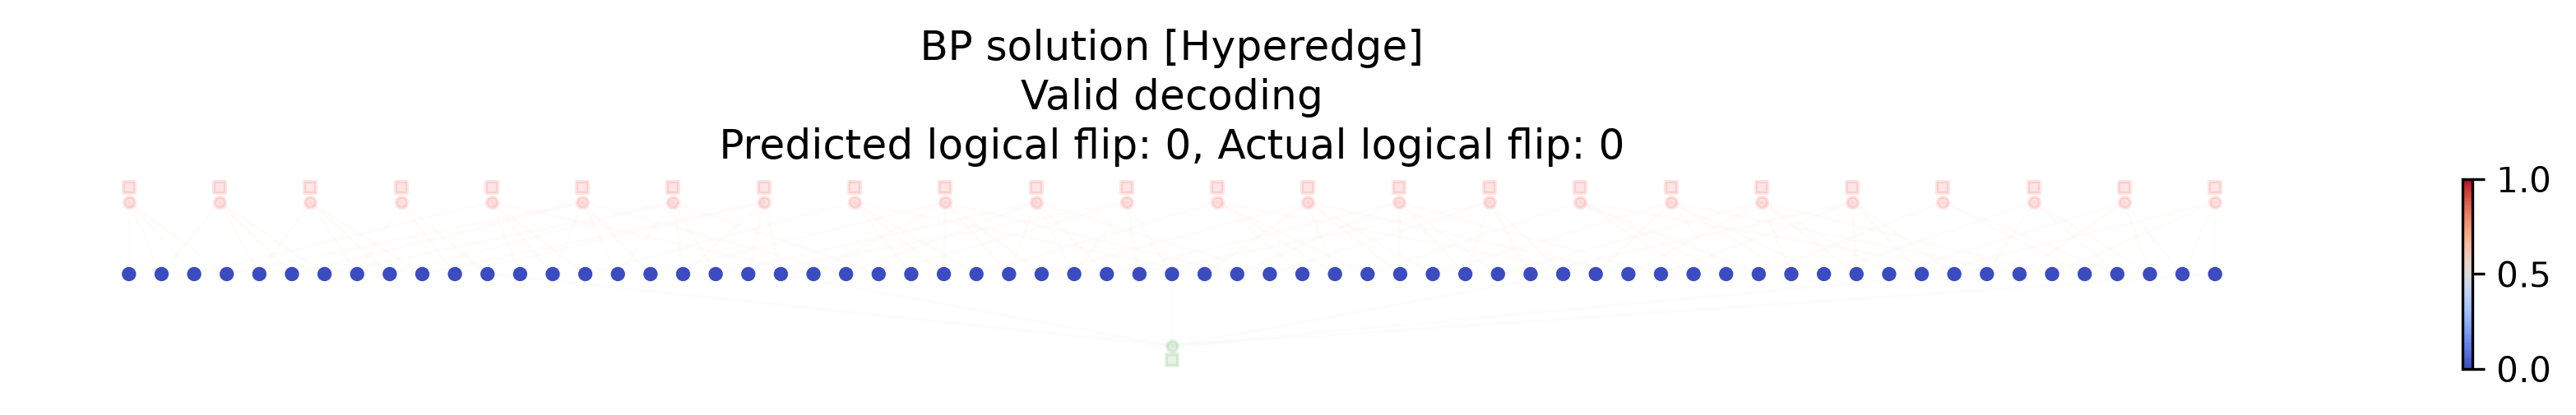

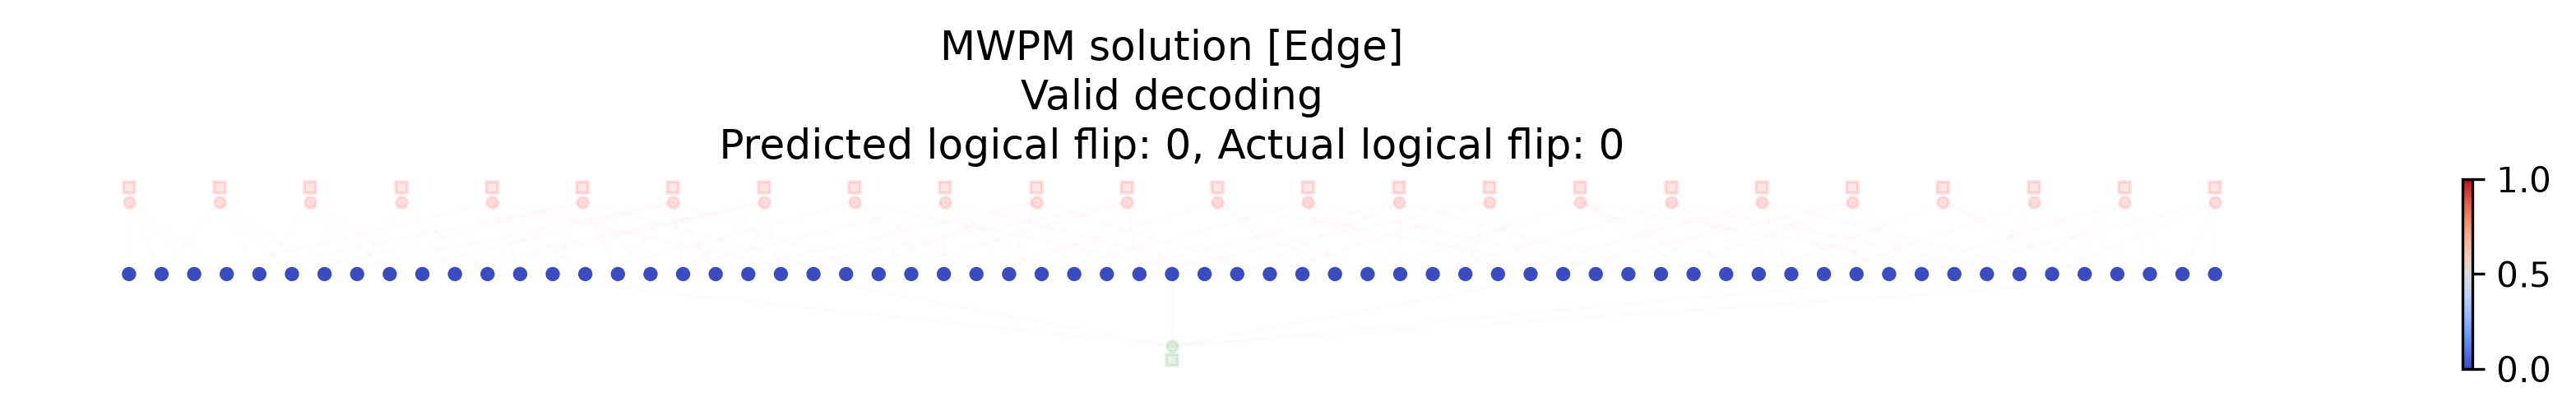

In [7]:
# Create a single shot of data to test the decoders on
sampler = qec_circ.compile_detector_sampler()
detector_events, observable_flips = sampler.sample(1, separate_observables=True)
logical_flip = observable_flips[0].astype(float) # Take the first (and only) shot and convert it to a float
syndrome = detector_events[0].astype(float) # Take the first (and only) shot and convert it to a float array for the BP decoder

# Run the BP decoder
bp_decoder = BaseBP(qec_circ)
posterior_belief = bp_decoder.decode(syndrome)
bp_probabilities = 1 / (1 + np.exp(posterior_belief))  # Convert to probability

# Run the MWPM decoder
mwpm_decoder = MWPM.from_check_matrix(
    check_matrix=bp_decoder.dem_matrix.edge_check_matrix,
    use_virtual_boundary_node=True,
) # We initialize it a bit different so it will give us the predicted error locations instead of the predicted logical flip
mwpm_correction = mwpm_decoder.decode(syndrome.astype(int))

# Visualize the Tanner graph and the messages for this single shot
helper_functions.tanner_graph(
    bp_decoder.check_matrix, 
    bp_decoder.observable_matrix, 
    syndrome, 
    logical_flip, 
    bp_probabilities, 
    "BP solution [Hyperedge]"
)
helper_functions.tanner_graph(
    bp_decoder.dem_matrix.edge_check_matrix, 
    bp_decoder.dem_matrix.edge_observables_matrix, 
    syndrome, 
    logical_flip, 
    mwpm_correction, 
    "MWPM solution [Edge]"
)


<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #7e57c2; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🧠 How to read the Tanner Graphs</h4>

**The top row (Check nodes):** The bright red circles indicate detectors that fired in our circuit while the faded out red circles indicate detectors that did not fire. The squares play a similar role but instead of indicating which detectors fired they indicate which detectors fired under the correction made by the decoder. The circles and squares should always match up under a valid decoding but if you run the cell enough times you may be able to find a case where the BP decoder did not find a valid solution. These are the cases where we would then ask some other decoder like the MWPM decoder to take over.

**The middle row (Variable nodes):** The cirles here indicate the error locations in the circuit. For the BP decoder, they are placed on a color bar which indicate the value of the calculated posterior probability for that node. For the MWPM decoder they are either 0/blue (no error) or 1/red (an error).

**The bottom row:** Same idea as the top row except it indicates the state of the logical qubit instead of the detectors. If the green circle is lit, it means we have know the physical errors in the QEC code resulted in an error on the logical information. If the green circle is lit, the decoder tells us to flip the logical information. That means if either non of them are lit or both of them are lit we correctly decoder the errors.

**The lines:** The lines shows the connections between the nodes that have been triggered.

</div>

## The assignment:

It is recommended that you start with implementing the `NumpyBP` decoder before attempting the `JaxBP` decoder. Use the template below as a starting point. The code is currently a copy of the `BaseBP` decoder, this allows you to focus on one function at a time and make sure that it is working correctly before moving on to the next one.

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #4CAF50; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🖥️ Implement the NumpyBP decoder class</h4>

In the following `NumpyBP` class you should replace the `for`-loops and `if`-statements with `numpy` array instructions. This should be done for the following two class functions:

- `message_from_v_to_c(self, msg_in: np.ndarray) -> np.ndarray:`

- `message_from_c_to_v(self,msg_in: np.ndarray,syndrome: np.ndarray) -> np.ndarray:`

Here is a list of numpy functions you may find helpfull:

- `np.sum(<your array>, axis=<axis to sum over>, where=<entries to include in the sum>)`: The sum of numbers in an array along a given axis and only including the entries dictated by `where`.

- `np.prod(<your array>, axis=<axis to sum over>, where=<entries to include in the sum>)`: The product of numbers in an array along a given axis and only including the entries dictated by `where`.

- `np.cumprod(<your array>, axis=<axis to sum over>)`: The cumulative product along a given axis: example `[a, b, c]` turns into `[a, ab, abc]`.

- `np.prod(<your array>, axis=<axis to sum over>, where=<entries to include in the sum>)`

- `np.broadcast_to(<your array>, <desired shape>)` Example: Array of shape `(a,)` to shape `(a,b)` is `np.broadcast_to(array[:,None], (a,b))` and Array of shape `(b,)` to shape `(a,b)` is `np.broadcast_to(array[None,:], (a,b))`.

**NOTE:** Start with the `message_from_v_to_c` function as that is the easier of the two. The `message_from_c_to_v` can be a bit more tricky as some of the incomming messages might be zero or close to zero which can cause numerical problems depending on how you implement it.

</div>

<details style="margin: 10px 0; padding: 8px 12px; border: 1px dashed var(--jp-border-color2, #aaa); border-radius: 6px;">
  <summary><strong>💡 Hint</strong></summary>

If you have an array like this one: `[a, b, c, d, e, f]` and want to take the product of all its elements excluding the current one (that is get an array like this `[b*c*d*e*f, a*c*d*e*f, a*b*d*e*f, a*b*c*e*f, a*b*c*d*f, a*b*c*d*e]`). You might be tempted to do something like this:

```python
msg = np.array([a,b,c,d,e,f]) # The input
prod_excl = np.prod(msg) / msg
prod_excl # The result
```

This will work most of the time but if any of the elements in `msg` is 0 you will run into problems. A more stable solution is to take the cumulative product from both directions in the following way:

```python
msg = np.array([a,b,c,d,e,f]) # The input
# Take the cumulative product from the left and from the right
cumprod_left = np.cumprod(msg)
cumprod_right = np.cumprod(msg[::-1])[::-1] # [::-1] reverses the array
# Computed the cumulative product excluding the current index
prod_excl = np.ones_like(msg)
prod_excl[1:] *= cumprod_left[:-1] # Adding the left part (a*b in the case of c)
prod_excl[:-1] *= cumprod_right[1:] # Adding the right part (d*e*f in the case of c)
prod_excl # The result
```

In this version of the code we completely avoid dividing by any of the elements so this will be robust no matter what values the `msg` array might include.

</details>


In [8]:
class NumpyBP:
    def __init__(self, stim_circuit: stim.Circuit, max_iterations: int = 20):
        """
        A numpy implementation of the message parsing functions from the BaseBP class.
        """
        dem = stim_circuit.detector_error_model(decompose_errors=True)
        self.dem_matrix = detector_error_model_to_check_matrices(dem)
        
        self.check_matrix = self.dem_matrix.check_matrix.toarray()
        self.observable_matrix = self.dem_matrix.observables_matrix.toarray()
        self.error_priors = self.dem_matrix.priors

        self.intrinsic_belief = np.log((1-self.error_priors) / self.error_priors)
        self.max_iterations = max_iterations
        
    # Send messages from variable nodes to check nodes
    def message_from_v_to_c(self, msg_in: np.ndarray) -> np.ndarray:
        msg_out = np.zeros_like(msg_in)
        # Loop over all edges in the Tanner graph and update the messages based on the incoming messages and the intrinsic belief for each variable node
        # TODO: Replace the for loops and if statements with numpy operations to make it faster
        for c in range(self.check_matrix.shape[0]):
            for v in range(self.check_matrix.shape[1]):
                if self.check_matrix[c, v] == 1:
                    # Create a mask for which messages to include in the sum
                    mask = self.check_matrix[:, v] == 1
                    # Remove the check node we are sending the message to from the mask
                    mask[c] = False
                    # Sum the messages from all check nodes connected to this variable node except the one we are sending the message to
                    summ = np.sum(msg_in[:, v][mask])
                    # Update the msg_out with the sum of the incoming messages and the intrinsic belief for this variable node
                    belief = self.intrinsic_belief[v]
                    msg_out[c, v] = belief + summ
        return msg_out

    # Send messages from check nodes to variable nodes
    def message_from_c_to_v(self,msg_in: np.ndarray,syndrome: np.ndarray) -> np.ndarray:
        msg_out = np.zeros_like(msg_in)
        # Loop over all edges in the Tanner graph and update the messages based on the incoming messages and the syndrome for each check node
        # TODO: Replace the for loops and if statements with numpy operations to make it faster
        for c in range(self.check_matrix.shape[0]):
            for v in range(self.check_matrix.shape[1]):
                if self.check_matrix[c, v] == 1:
                    # Create a mask for which messages to include in the product
                    mask = self.check_matrix[c, :] == 1
                    # Remove the variable node we are sending the message to from the mask
                    mask[v] = False
                    # Compute the product of the incoming messages from all variable nodes connected to this check node except the one we are sending the message to
                    prod = np.prod(np.tanh(msg_in[c, :] / 2), where=mask)
                    # Update the msg_out with the product of the incoming messages and the syndrome for this check node
                    factor = (-1)**syndrome[c]
                    msg_out[c, v] = factor * 2 * np.arctanh(prod)
        return msg_out

    # Run the full message passing loop
    def decode(self, syndrome: np.ndarray) -> np.ndarray:
        # Initialize messages from check nodes to variable nodes to zero
        msg_c_v = np.zeros((self.check_matrix.shape[0], self.check_matrix.shape[1]))
        msg_c_v_old = msg_c_v.copy() + 1 # Ensure that the messages are not equal at the start of the iterations (will be overwritten in the first iteration so the content is not important)
        # Run belief propagation iterations until convergence or max iterations reached
        current_iteration = 0
        while current_iteration < self.max_iterations and not np.allclose(msg_c_v, msg_c_v_old):
            current_iteration += 1 # Increment the iteration counter
            msg_v_c = self.message_from_v_to_c(msg_c_v)
            msg_c_v_old = msg_c_v.copy() # Store the old messages to check for convergence
            msg_c_v = self.message_from_c_to_v(msg_v_c, syndrome)
        # Compute the final posterior belief for each variable node
        posterior_belief = self.intrinsic_belief + np.sum(msg_c_v, axis=0)
        return posterior_belief
    
    # Decode a batch of syndromes
    def decode_batch(self, syndromes: np.ndarray) -> np.ndarray:
        # Decode a batch of syndromes by calling the decode function for each syndrome in the batch
        return np.array([self.decode(syndrome) for syndrome in syndromes])

A quick way to ensure that your `NumpyBP` decoder gives the same results as the `BaseBP` decoder:

In [16]:
num_tests = 10 # Number of random syndromes to test the decoders on
max_prints = 10 # Maximum number of test results to print (usefull for large values of num_tests)

# Initialize the decoders
base_bp = BaseBP(qec_circ)
numpy_bp = NumpyBP(qec_circ)

# Sample the circuit and test the decoder
sampler = qec_circ.compile_detector_sampler()
detector_events, observable_flips = sampler.sample(shots=num_tests, separate_observables=True)
observable_flip = observable_flips.astype(float)  # Get the observable flip for the first shot
syndromes = detector_events.astype(float)  # Get the syndrome for the first shot

# Run both decoders
t0 = perf_counter_ns()
base_bp_posteriors = base_bp.decode_batch(syndromes)
t1 = perf_counter_ns()
numpy_bp_posteriors = numpy_bp.decode_batch(syndromes)
t2 = perf_counter_ns()

# Compute times
base_bp_time_ms = (t1-t0)/1e6
numpy_bp_time_ms = (t2-t1)/1e6
print(f" BaseBP time: {base_bp_time_ms:10.2f} ms")
print(f"NumpyBP time: {numpy_bp_time_ms:10.2f} ms ({(base_bp_time_ms)/(numpy_bp_time_ms):6.1f}x faster than baseline)")

# Compare the results
print()
for i, (base_bp_posterior, numpy_bp_posterior) in enumerate(zip(base_bp_posteriors[:max_prints], numpy_bp_posteriors[:max_prints])):
    print(f"{f'Test {i+1}/{num_tests}':s}:\t", end="")
    if np.allclose(base_bp_posterior, numpy_bp_posterior):
        print("Posteriors match!")
    else:
        print(f"ERROR: Posteriors do not match: {np.max(base_bp_posterior - numpy_bp_posterior):.10f}")

 BaseBP time:     265.02 ms
NumpyBP time:     269.74 ms (   1.0x faster than baseline)

Test 1/10:	Posteriors match!
Test 2/10:	Posteriors match!
Test 3/10:	Posteriors match!
Test 4/10:	Posteriors match!
Test 5/10:	Posteriors match!
Test 6/10:	Posteriors match!
Test 7/10:	Posteriors match!
Test 8/10:	Posteriors match!
Test 9/10:	Posteriors match!
Test 10/10:	Posteriors match!


<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #ccc; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>📝 Conclusion?</h4>

Your answer goes here...

</div>

---

This one is optional but you can get quite a lot of extra performance out of it with minimul work so it is highly encouraged to do

<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #4CAF50; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>🖥️ Implement the JaxBP decoder class</h4>

Copy over your `NumpyBP` class and rename it to `JaxBP` and do the following to make it really fast. Remember to test it after each change you make to catch any errors early on.

1) Replace `np` with `jnp`. At places where you asign values like `A[i] = B` it will now be `A.at[i].set(B)` as the objects jax arrays imutable

2) After everything works you can make it even faster by compiling every function. This is done with the following decorator:

    This:

    ```python
    def fun(self, args):
    ```

    becomes this:
    
    ```python
    @partial(jit, static_argnums=0) # Do not include the self in the jit-compilation since it is not jit-compilable
    def fun(self, args):
    ```

    NOTE: In the `decode` you may need to replace the `while`-loop with a `for`-loop and no `if`-statements (meaning always doing the max number of iterations even if it converges early) in order to be able to `@jit`-compile it.

3) The final step is to vectorize (paralize) over all the syndromes given to the `decode_batch` function using the `vmap` function.

</div>

In [11]:
import jax.numpy as jnp
from jax import jit, vmap, config as jax_config
jax_config.update("jax_enable_x64", True)
from functools import partial

In [12]:
# Copy the NumpyBP class you implemented above and modify it to use jax.numpy and the @partial(jit, static_argnums=0) decorator to make it faster.
JaxBP = NumpyBP 

The speedup should become more significant as you increase the `num_tests` as thats where the batch decoding paralization can really do its work.

In [17]:
num_tests = 1000 # Number of random syndromes to test the decoders on
max_prints = 10 # Maximum number of test results to print (usefull for large values of num_tests)

# Initialize the decoders
numpy_bp = NumpyBP(qec_circ)
jax_bp = JaxBP(qec_circ)

# Sample the circuit and test the decoder
sampler = qec_circ.compile_detector_sampler()
detector_events, observable_flips = sampler.sample(shots=num_tests, separate_observables=True)
observable_flip = observable_flips.astype(float)  # Get the observable flip for the first shot
syndromes = detector_events.astype(float)  # Get the syndrome for the first shot

# Warm up the JIT compiler by running the decoder once before timing
# This is how JIT compilation works: the first time you call a JIT-compiled function, 
# it compiles the function for the given input shapes and types, which can take some time. 
# Subsequent calls with the same input shapes and types will be much faster because they 
# will use the compiled version of the function. By running the decoder once before timing, 
# we ensure that we are measuring the time it takes to run the compiled version of the function, 
# rather than including the compilation time in our measurements.
_ = jax_bp.decode_batch(syndromes)

# Run both decoders
t0 = perf_counter_ns()
numpy_bp_posteriors = numpy_bp.decode_batch(syndromes)
t1 = perf_counter_ns()
jax_bp_posteriors = jax_bp.decode_batch(syndromes)
t2 = perf_counter_ns()

# Compute times
numpy_bp_time_ms = (t1-t0)/1e6
jax_bp_time_ms = (t2-t1)/1e6
print(f"NumpyBP time: {numpy_bp_time_ms:10.2f} ms")
print(f"  JaxBP time: {jax_bp_time_ms:10.2f} ms ({(numpy_bp_time_ms)/(jax_bp_time_ms):6.1f}x faster than baseline)")

# Compare the results
print()
for i, (numpy_bp_posterior, jax_bp_posterior) in enumerate(zip(numpy_bp_posteriors[:max_prints], jax_bp_posteriors[:max_prints])):
    print(f"{f'Test {i+1}/{num_tests}':s}:\t", end="")
    if np.allclose(numpy_bp_posterior, jax_bp_posterior):
        print("Posteriors match!")
    else:
        print("ERROR: Posteriors do not match.")
        print(f"Difference in posterior: {np.linalg.norm(numpy_bp_posterior - jax_bp_posterior)}")

NumpyBP time:   50628.92 ms
  JaxBP time:   78027.05 ms (   0.6x faster than baseline)

Test 1/1000:	Posteriors match!
Test 2/1000:	Posteriors match!
Test 3/1000:	Posteriors match!
Test 4/1000:	Posteriors match!
Test 5/1000:	Posteriors match!
Test 6/1000:	Posteriors match!
Test 7/1000:	Posteriors match!
Test 8/1000:	Posteriors match!
Test 9/1000:	Posteriors match!
Test 10/1000:	Posteriors match!


<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #ccc; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>📝 Conclusion:</h4>

Your answer goes here...

</div>

# Compare the LERs of the QEC code between the MWPM (PyMatching) decoder and the BP decoder

In [18]:
def BP_decode_ler(
    qec_circuit: stim.Circuit,
    bp_class: NumpyBP,
    detection_events: np.ndarray,
    observable_flips: np.ndarray,
):
    dem_matrix = detector_error_model_to_check_matrices(qec_circuit.detector_error_model(decompose_errors=True))

    # Decode using the BP decoder first
    bp_decoder: NumpyBP = bp_class(qec_circuit)
    posterior_beliefs = np.array(bp_decoder.decode_batch(detection_events.astype(float)))
    predicted_errors = posterior_beliefs < 0
    predicted_syndromes = (dem_matrix.check_matrix @ predicted_errors.T).T % 2
    predicted_logical_flips = (dem_matrix.observables_matrix @ predicted_errors.T).T % 2
    found_valid_solution = np.all(predicted_syndromes == detection_events.astype(float), axis=1)

    # Exclude result where BP did not find a valid solution
    ler = np.mean(predicted_logical_flips[found_valid_solution] != observable_flips[found_valid_solution])
    return ler, found_valid_solution

def MWPM_decode_ler(
    qec_circuit: stim.Circuit,
    detection_events: np.ndarray,
    observable_flips: np.ndarray,
):
    mwpm_decoder = MWPM.from_stim_circuit(qec_circuit)
    predicted_logical_flips = np.array([mwpm_decoder.decode(syndrome.astype(int)) for syndrome in detection_events])
    ler = np.mean(predicted_logical_flips != observable_flips)
    return ler

shots = 10000
sampler = qec_circ.compile_detector_sampler()
detector_events, observable_flips = sampler.sample(shots, separate_observables=True)

# The BP LER only includes the cases where BP found a valid solution
bp_ler, found_valid_solution = BP_decode_ler(qec_circ, JaxBP, detector_events, observable_flips)
# To keep the comparison fair we will also compute the MWPM (PyMatching) LER only on the cases where BP found a valid solution
mwpm_ler = MWPM_decode_ler(qec_circ, detector_events[found_valid_solution], observable_flips[found_valid_solution])

print(f"BP Success Rate:  {found_valid_solution.mean():6.2%}")
print("------------------------")
print(f"BP Decoder LER:   {bp_ler:6.2%}")
print(f"MWPM Decoder LER: {mwpm_ler:6.2%}")

BP Success Rate:  97.32%
------------------------
BP Decoder LER:    0.06%
MWPM Decoder LER:  0.06%


<div style="border: 1px solid var(--jp-border-color2, #ccc); border-left: 6px solid #ccc; padding: 12px; border-radius: 6px; margin: 10px 0;">
<h4>📝 Conclusion?</h4>

Your answer goes here...

</div>